# TC5061 - Notebook EDA
**Alumno:** Dan García
**Dataset:** SBA National Loans - U.S. Small Business Administration (Kaggle)
**Objetivo:** Predecir si un préstamo otorgado a una pequeña empresa caerá en incumplimiento (default), recorriendo el flujo completo de un proyecto de ML con registro de experimentos en MLflow.

In [1]:
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import kagglehub

# Semilla global para reproducibilidad
SEED = 42
np.random.seed(SEED)

# Configuración visual
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

# Registro de versiones para reproducibilidad
print(f"pandas: {pd.__version__} | sklearn: {sklearn.__version__}")

/Users/dangarcia/mna-mlops/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


pandas: 3.0.6 | sklearn: 1.9.1 | mlflow: 3.16.1


## Paso 1. Carga y descripción del dataset

El dataset contiene el histórico de préstamos a pequeñas empresas garantizados por la U.S. Small Business Administration (SBA) entre 1962 y 2014. Cada registro es un préstamo.

**Tipo de problema:** clasificación binaria supervisada.
**Variable objetivo:** `MIS_Status` - indica si el préstamo se pagó completo (`P I F`) o cayó en incumplimiento (`CHGOFF`).

In [2]:
DATASET_ID = "mirbektoktogaraev/should-this-loan-be-approved-or-denied"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
RAW_FILE = DATA_DIR / "SBAnational.csv"

# Descarga solo si no existe la copia local (evita descargas repetidas)
if not RAW_FILE.exists():
    cache_path = Path(kagglehub.dataset_download(DATASET_ID))
    print("Archivos descargados:", [f.name for f in cache_path.iterdir()])
    shutil.copy(cache_path / "SBAnational.csv", RAW_FILE)

# low_memory=False para evitar que pandas infiera tipos distintos por bloques
df_raw = pd.read_csv(RAW_FILE, low_memory=False)

print(f"Registros: {df_raw.shape[0]:,} | Variables: {df_raw.shape[1]}")
df_raw.head()

Registros: 899,164 | Variables: 27


,LoanNr_ChkDgt,Name,City,State,Zip,Bank,BankState,NAICS,ApprovalDate,ApprovalFY,Term,NoEmp,NewExist,CreateJob,RetainedJob,FranchiseCode,UrbanRural,RevLineCr,LowDoc,ChgOffDate,DisbursementDate,DisbursementGross,BalanceGross,MIS_Status,ChgOffPrinGr,GrAppv,SBA_Appv
0,1000014003,ABC HOBBYCRAFT,EVANSVILLE,IN,47711,FIFTH THIRD BANK,OH,451120,28-Feb-97,1997,84,4,2.0,0,0,1,0,N,Y,NaN,28-Feb-99,"$60,000.00",$0.00,P I F,$0.00,"$60,000.00","$48,000.00"
1,1000024006,LANDMARK BAR & GRILLE (THE),NEW PARIS,IN,46526,1ST SOURCE BANK,IN,722410,28-Feb-97,1997,60,2,2.0,0,0,1,0,N,Y,NaN,31-May-97,"$40,000.00",$0.00,P I F,$0.00,"$40,000.00","$32,000.00"
2,1000034009,"WHITLOCK DDS, TODD M.",BLOOMINGTON,IN,47401,GRANT COUNTY STATE BANK,IN,621210,28-Feb-97,1997,180,7,1.0,0,0,1,0,N,N,NaN,31-Dec-97,"$287,000.00",$0.00,P I F,$0.00,"$287,000.00","$215,250.00"
3,1000044001,"BIG BUCKS PAWN & JEWELRY, LLC",BROKEN ARROW,OK,74012,1ST NATL BK & TR CO OF BROKEN,OK,0,28-Feb-97,1997,60,2,1.0,0,0,1,0,N,Y,NaN,30-Jun-97,"$35,000.00",$0.00,P I F,$0.00,"$35,000.00","$28,000.00"
4,1000054004,"ANASTASIA CONFECTIONS, INC.",ORLANDO,FL,32801,FLORIDA BUS. DEVEL CORP,FL,0,28-Feb-97,1997,240,14,1.0,7,7,1,0,N,N,NaN,14-May-97,"$229,000.00",$0.00,P I F,$0.00,"$229,000.00","$229,000.00"


In [3]:
# Tipos de dato, conteo de no nulos y uso de memoria
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 899164 entries, 0 to 899163
Data columns (total 27 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   LoanNr_ChkDgt      899164 non-null  int64  
 1   Name               899150 non-null  str    
 2   City               899134 non-null  str    
 3   State              899150 non-null  str    
 4   Zip                899164 non-null  int64  
 5   Bank               897605 non-null  str    
 6   BankState          897598 non-null  str    
 7   NAICS              899164 non-null  int64  
 8   ApprovalDate       899164 non-null  str    
 9   ApprovalFY         899164 non-null  str    
 10  Term               899164 non-null  int64  
 11  NoEmp              899164 non-null  int64  
 12  NewExist           899028 non-null  float64
 13  CreateJob          899164 non-null  int64  
 14  RetainedJob        899164 non-null  int64  
 15  FranchiseCode      899164 non-null  int64  
 16  UrbanRural   

In [4]:
# Resumen por variable: tipo, nulos, cardinalidad y un ejemplo real
resumen = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "no_nulos": df_raw.notna().sum(),
    "pct_nulos": (df_raw.isna().mean() * 100).round(2),
    "valores_unicos": df_raw.nunique(),
    "ejemplo": df_raw.apply(lambda c: c.dropna().iloc[0]),
})
resumen.sort_values("pct_nulos", ascending=False)

,tipo,no_nulos,pct_nulos,valores_unicos,ejemplo
ChgOffDate,str,162699,81.91,6448,24-Jun-91
RevLineCr,str,894636,0.50,18,N
LowDoc,str,896582,0.29,8,Y
DisbursementDate,str,896796,0.26,8472,28-Feb-99
MIS_Status,str,897167,0.22,2,P I F
Bank,str,897605,0.17,5802,FIFTH THIRD BANK
BankState,str,897598,0.17,56,OH
NewExist,float64,899028,0.02,3,2.0
LoanNr_ChkDgt,int64,899164,0.00,899164,1000014003
FranchiseCode,int64,899164,0.00,2768,1


In [5]:
# Distribución de la variable objetivo (incluyendo nulos)
pd.DataFrame({
    "conteo": df_raw["MIS_Status"].value_counts(dropna=False),
    "porcentaje": (df_raw["MIS_Status"].value_counts(dropna=False, normalize=True) * 100).round(2),
})

,conteo,porcentaje
MIS_Status,,
P I F,739609,82.26
CHGOFF,157558,17.52
NaN,1997,0.22


### Diccionario de datos

| Grupo | Variable | Significado | Tipo actual | Tipo correcto |
|---|---|---|---|---|
| Identificador | `LoanNr_ChkDgt` | ID único del préstamo | int | ID (se excluye) |
| Prestatario | `Name` | Nombre de la empresa | str | ID (se excluye) |
| | `City`, `State`, `Zip` | Ubicación de la empresa | str / int | Categórica |
| Banco | `Bank`, `BankState` | Banco otorgante y su estado | str | Categórica |
| Empresa | `NAICS` | Código de industria (0 = no registrado) | int | Categórica (sector = 2 primeros dígitos) |
| | `NoEmp` | Número de empleados | int | Numérica |
| | `NewExist` | 1 = empresa existente, 2 = nueva | float | Categórica |
| | `CreateJob`, `RetainedJob` | Empleos creados / retenidos | int | Numérica |
| | `FranchiseCode` | 0 o 1 = no es franquicia | int | Binaria |
| | `UrbanRural` | 1 = urbano, 2 = rural, 0 = no definido | int | Categórica |
| Préstamo | `ApprovalDate`, `ApprovalFY` | Fecha y año fiscal de aprobación | str | Fecha / numérica |
| | `Term` | Plazo en meses | int | Numérica |
| | `RevLineCr` | Línea de crédito revolvente (Y/N) | str | Binaria |
| | `LowDoc` | Programa de documentación simplificada (Y/N) | str | Binaria |
| | `DisbursementDate` | Fecha de desembolso | str | Fecha |
| | `DisbursementGross` | Monto desembolsado | str (`$`) | Numérica |
| | `GrAppv` | Monto aprobado por el banco | str (`$`) | Numérica |
| | `SBA_Appv` | Monto garantizado por la SBA | str (`$`) | Numérica |
| Resultado | `BalanceGross` | Saldo pendiente | str (`$`) | Numérica |
| | `ChgOffDate` | Fecha en que se declaró el default | str | **Fuga de información** |
| | `ChgOffPrinGr` | Monto perdido por default | str (`$`) | **Fuga de información** |
| | `MIS_Status` | Estatus final del préstamo | str | **Variable objetivo** |

### Hallazgos iniciales
- **Desbalance de clases:** 82.26% de los préstamos se pagaron (`P I F`) y 17.52% cayeron en default (`CHGOFF`). Accuracy no será una métrica suficiente: un modelo que siempre predice "pagado" ya obtendría ~82%.
- **1,997 registros (0.22%) sin variable objetivo:** no son utilizables para aprendizaje supervisado.
- **Fuga de información:** `ChgOffDate` (81.91% nulos) y `ChgOffPrinGr` solo tienen valor cuando el default ya ocurrió. Se excluyen del modelo.
- **Faltantes disfrazados:** `NewExist` y `UrbanRural` usan `0` como "no definido"; `RevLineCr` (18 valores) y `LowDoc` (8 valores) contienen códigos fuera de Y/N.
- **Tipos incorrectos:** montos con formato moneda (`$60,000.00`), fechas como texto y `ApprovalFY` como texto.
- **Variables sin valor predictivo:** identificadores (`LoanNr_ChkDgt`, `Name`) y `BalanceGross` (casi constante).

## Paso 2. Análisis exploratorio (EDA)

Para explorar se crea una copia (`df_eda`) con conversiones mínimas: montos a numérico, variable objetivo a binaria (1 = default) y sector industrial a partir de NAICS. El dataset original (`df_raw`) no se modifica; la limpieza formal se realiza en el Paso 3.

In [6]:
# Copia exploratoria: solo registros con variable objetivo conocida
df_eda = df_raw.dropna(subset=["MIS_Status"]).copy()

# Variable objetivo binaria: 1 = default (CHGOFF), 0 = pagado (P I F)
df_eda["default"] = (df_eda["MIS_Status"] == "CHGOFF").astype(int)

# Montos con formato moneda -> numérico
money_cols = ["DisbursementGross", "GrAppv", "SBA_Appv"]
for col in money_cols:
    df_eda[col] = df_eda[col].str.replace(r"[\$,\s]", "", regex=True).astype(float)

# Año fiscal: extraer los 4 dígitos (algunos valores traen letras)
df_eda["ApprovalFY"] = pd.to_numeric(df_eda["ApprovalFY"].astype(str).str.extract(r"(\d{4})")[0])

# Sector industrial: 2 primeros dígitos de NAICS (0 = no registrado)
df_eda["sector"] = np.where(df_eda["NAICS"] == 0, "No registrado", df_eda["NAICS"].astype(str).str[:2])

print(f"Registros para EDA: {len(df_eda):,} | Tasa de default: {df_eda['default'].mean():.2%}")

Registros para EDA: 897,167 | Tasa de default: 17.56%


In [7]:
# Estadísticas descriptivas de variables numéricas relevantes
num_cols = ["Term", "NoEmp", "CreateJob", "RetainedJob"] + money_cols
df_eda[num_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T.round(1)

,count,mean,std,min,25%,50%,75%,95%,99%,max
Term,897167.0,110.8,78.9,0.0,60.0,84.0,120.0,300.0,300.0,569.0
NoEmp,897167.0,11.4,73.8,0.0,2.0,4.0,10.0,40.0,95.0,9999.0
CreateJob,897167.0,8.4,237.0,0.0,0.0,0.0,1.0,10.0,30.0,8800.0
RetainedJob,897167.0,10.8,237.4,0.0,0.0,1.0,4.0,20.0,55.0,9500.0
DisbursementGross,897167.0,201598.0,287806.6,4000.0,42492.0,100000.0,239000.0,763000.0,1367000.0,11446325.0
GrAppv,897167.0,193059.5,283433.1,1000.0,35000.0,90000.0,225000.0,750000.0,1350000.0,5472000.0
SBA_Appv,897167.0,149780.7,228560.0,500.0,21250.0,62050.0,175000.0,627300.0,1000000.0,5472000.0


**Análisis:**
Los montos están muy cargados hacia la derecha: el promedio aprobado (`GrAppv`) anda en ~193K, pero la mediana está en 90K. O sea, la mayoría son préstamos chicos y unos pocos muy grandes jalan el promedio hacia arriba.

También salen valores raros que hay que revisar en la limpieza:
- `Term` tiene préstamos con plazo de 0 meses, lo cual no tiene mucho sentido.
- `NoEmp` llega a 9,999 empleados, que huele a valor de relleno más que a un dato real.
- `CreateJob` y `RetainedJob` tienen máximos de 8,800 y 9,500 cuando la mediana es 0 y 1. Son outliers claros.

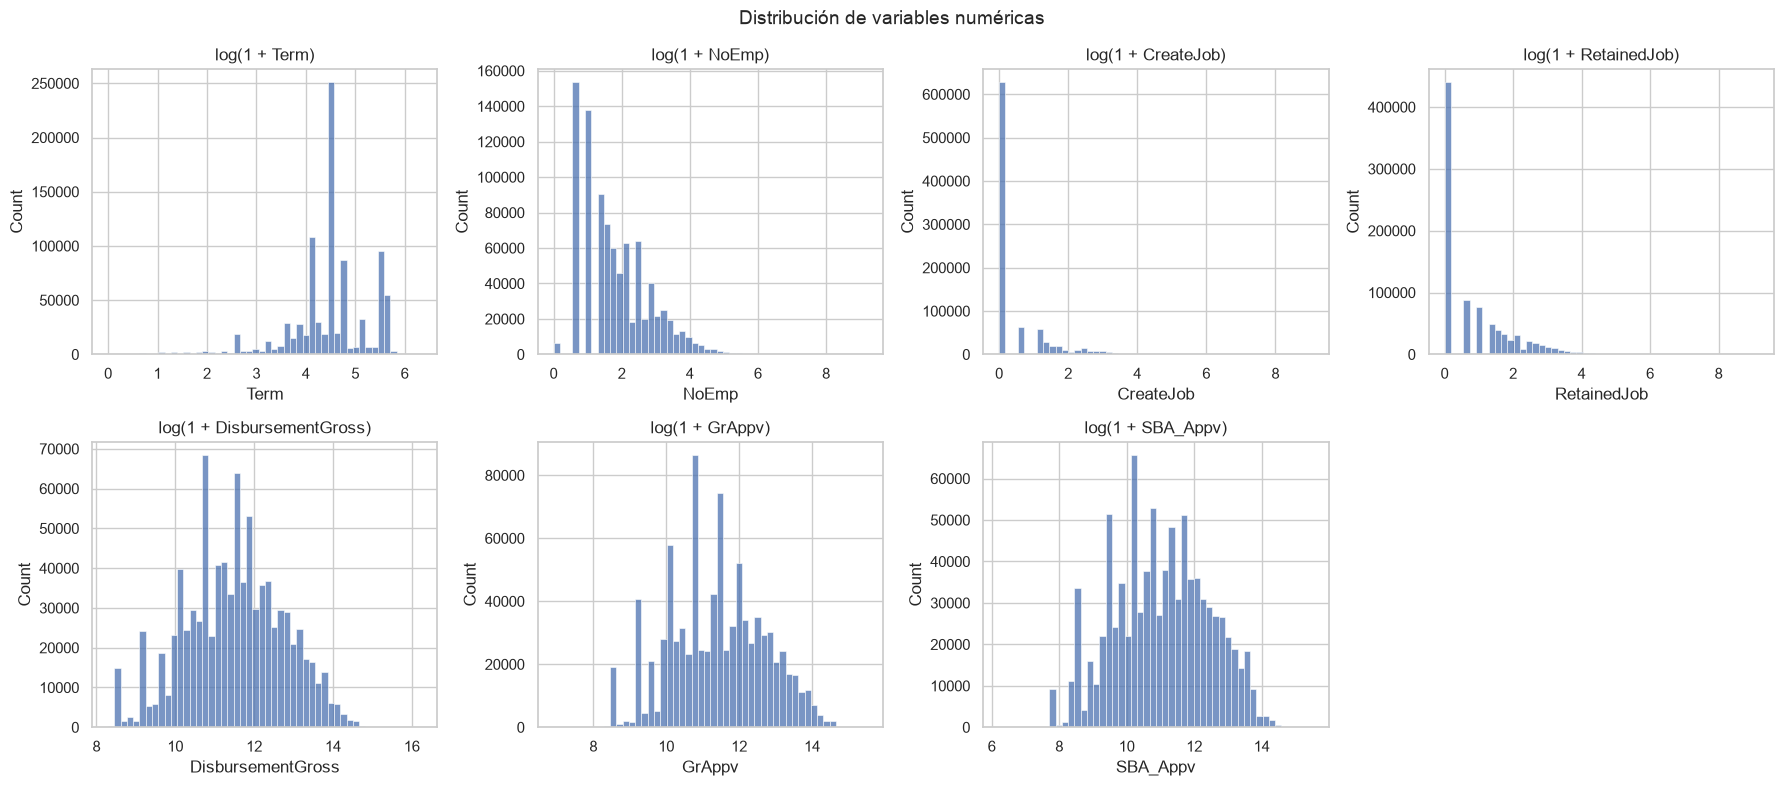

In [8]:
# Distribución de variables numéricas (escala log por fuerte asimetría)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(np.log1p(df_eda[col]), bins=50, ax=ax)
    ax.set_title(f"log(1 + {col})")
axes.flat[-1].axis("off")
plt.suptitle("Distribución de variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

**Análisis:**
Usé escala logarítmica porque sin ella las gráficas quedaban aplastadas por los valores extremos.

- `Term` no es continuo: se concentra en plazos "estándar" (el pico más alto es 84 meses, 7 años), lo que tiene sentido porque los bancos ofrecen productos con plazos fijos.
- Los montos se ven más o menos normales en escala log, con picos en cantidades redondas (50K, 100K, etc.). Otra vez, así se negocian los préstamos en la vida real.
- `CreateJob` y `RetainedJob` son casi siempre 0, así que probablemente aporten poca información al modelo.

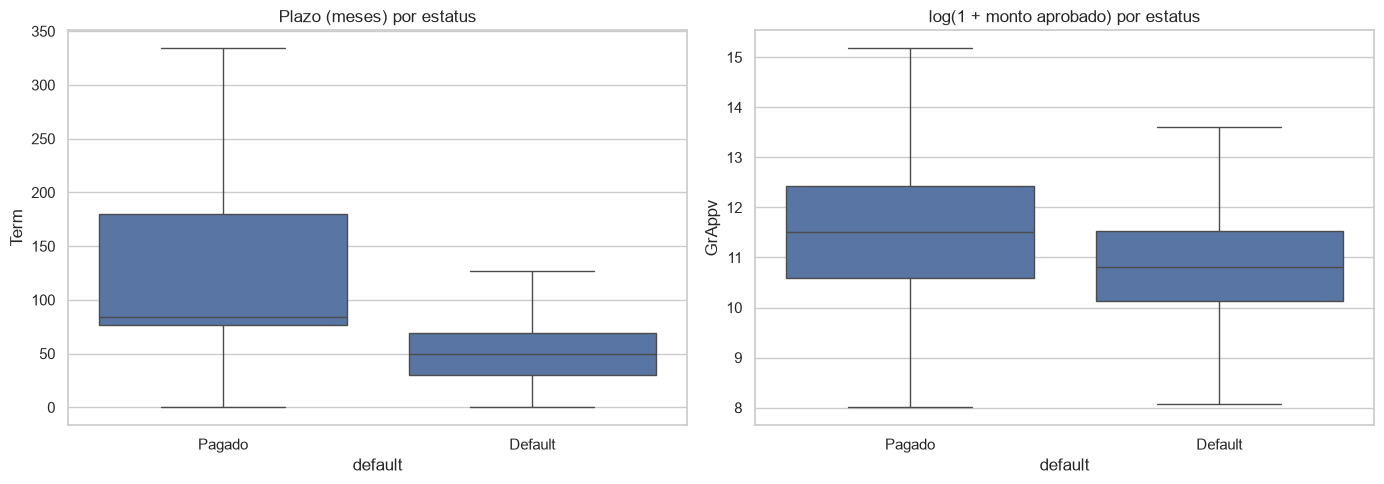

In [9]:
# Comparación de plazo y monto entre préstamos pagados y en default
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df_eda, x="default", y="Term", ax=axes[0], showfliers=False)
axes[0].set_title("Plazo (meses) por estatus")
sns.boxplot(data=df_eda, x="default", y=np.log1p(df_eda["GrAppv"]), ax=axes[1], showfliers=False)
axes[1].set_title("log(1 + monto aprobado) por estatus")
for ax in axes:
    ax.set_xticks([0, 1], ["Pagado", "Default"])
plt.tight_layout()
plt.show()

**Análisis:**
Esta es de las gráficas más claras del EDA. Los préstamos en default tienen plazos mucho más cortos: la mediana anda cerca de 50 meses contra 84 de los pagados, y casi no hay defaults arriba de 125 meses.

Mi hipótesis es que los plazos largos (20-25 años) suelen ser préstamos respaldados por bienes raíces, que tienen garantía y por eso fallan menos. Con el monto pasa algo parecido pero más leve: los préstamos que caen en default tienden a ser un poco más chicos.

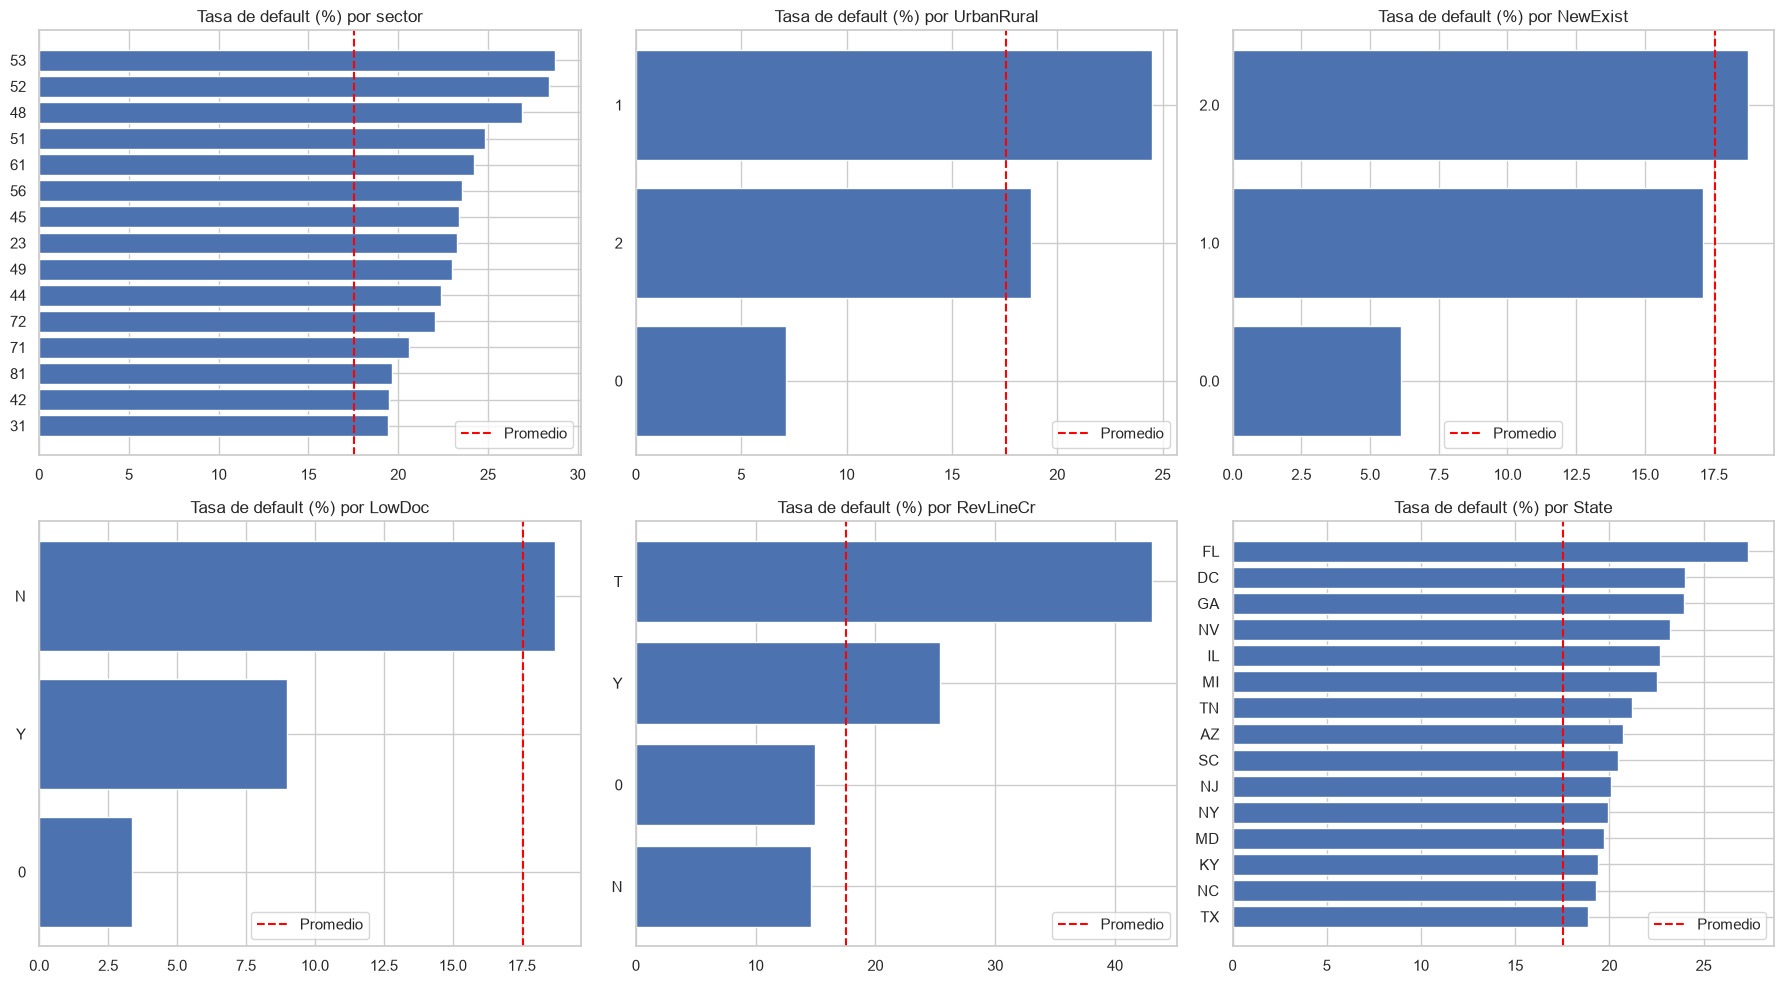

In [10]:
# Tasa de default por categoría (solo categorías con al menos 1,000 préstamos)
def tasa_default(col, ax, top=15):
    t = df_eda.groupby(col)["default"].agg(tasa="mean", n="size")
    t = t[t["n"] >= 1000].sort_values("tasa", ascending=False).head(top)
    ax.barh(t.index.astype(str), t["tasa"] * 100)
    ax.axvline(df_eda["default"].mean() * 100, ls="--", c="red", label="Promedio")
    ax.invert_yaxis()
    ax.set_title(f"Tasa de default (%) por {col}")
    ax.legend()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, ["sector", "UrbanRural", "NewExist", "LowDoc", "RevLineCr", "State"]):
    tasa_default(col, ax)
plt.tight_layout()
plt.show()

**Análisis:**
- **Sector:** bienes raíces (53), finanzas (52) y transporte (48) son los más riesgosos, cerca de 27-29% de default. Ojo: la gráfica solo muestra los 15 sectores con más default, por eso todos quedan arriba del promedio.
- **UrbanRural y NewExist:** el código `0` ("no definido") tiene tasas bajísimas (~6-7%). No creo que sea casualidad: lo más probable es que esos registros sean préstamos antiguos donde el dato no se capturaba, y esos años tuvieron poco default. O sea, el `0` no es un faltante cualquiera, trae información escondida del año.
- **LowDoc y RevLineCr:** además de Y/N aparecen códigos como `0` y `T`, y `T` llega a ~43% de default. Hay que decidir en la limpieza qué hacer con ellos.
- **Estado:** Florida, Georgia y Nevada están arriba, que justo fueron estados muy golpeados por la crisis inmobiliaria de 2008.

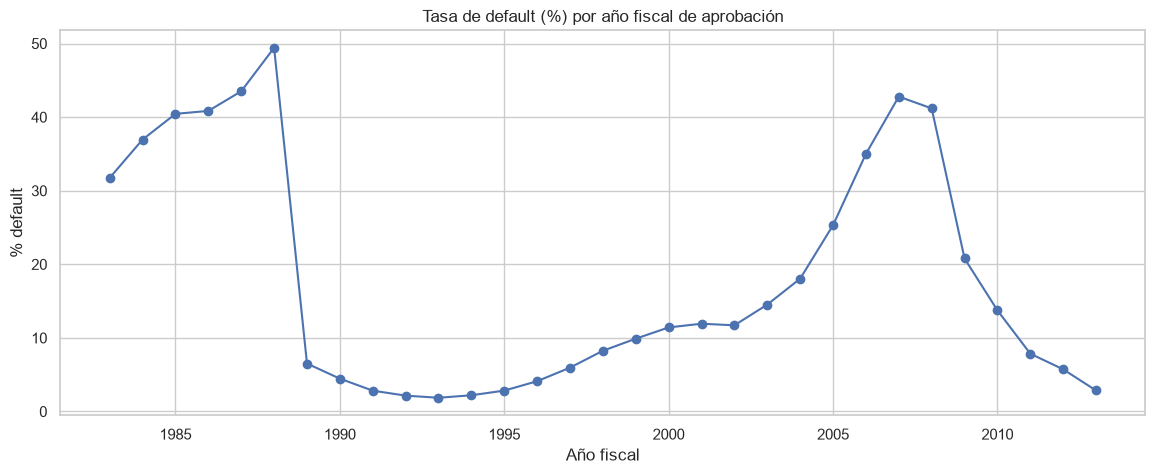

In [11]:
# Evolución de la tasa de default por año fiscal de aprobación
anual = df_eda.groupby("ApprovalFY")["default"].agg(tasa="mean", n="size")
anual = anual[anual["n"] >= 1000]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(anual.index, anual["tasa"] * 100, marker="o")
ax.set_title("Tasa de default (%) por año fiscal de aprobación")
ax.set_xlabel("Año fiscal")
ax.set_ylabel("% default")
plt.show()

**Análisis:**
El default cambia muchísimo según el año en que se aprobó el préstamo:
- 1983-1988: tasas altísimas (30-50%).
- 1989-1997: casi nada, abajo del 5%.
- 2004-2008: sube fuerte hasta ~43% en 2007. Son préstamos aprobados justo antes de la crisis financiera.
- Después de 2009 baja otra vez.

Un detalle importante: los préstamos más recientes (2010+) probablemente se ven "sanos" porque el dataset se cortó en 2014 y no les dio tiempo de fallar. Esto me dice que el contexto económico pesa mucho, y que un split aleatorio entre train y test puede dar resultados más optimistas que lo que pasaría prediciendo préstamos nuevos.

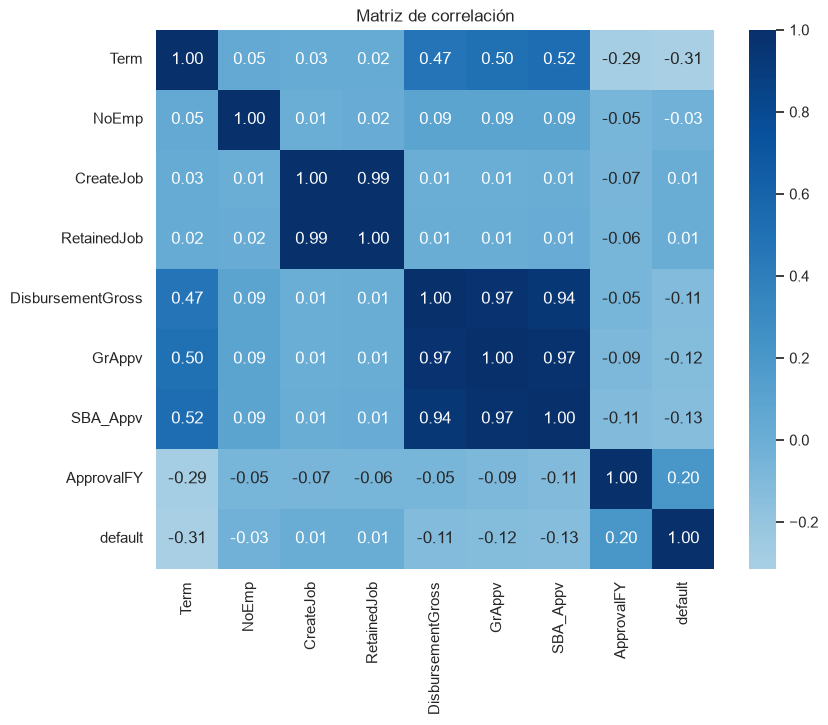

In [12]:
# Correlación entre variables numéricas y la variable objetivo
corr = df_eda[num_cols + ["ApprovalFY", "default"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", center=0)
plt.title("Matriz de correlación")
plt.show()

**Análisis:**
- `Term` es la variable con más relación lineal con el default (-0.31): a más plazo, menos riesgo. Cuadra con lo que vimos en los boxplots.
- `ApprovalFY` tiene 0.20, confirmando que el año importa.
- Los tres montos están correlacionados entre sí arriba de 0.94, prácticamente dicen lo mismo. Igual con `CreateJob` y `RetainedJob` (0.99). Para un modelo lineal esto puede meter ruido, así que conviene quedarse con una variable de cada grupo.
- `NoEmp` casi no tiene relación lineal con el default.

Hay que tener en cuenta que esta matriz solo captura relaciones lineales entre numéricas; varias de las señales más fuertes (sector, estado, LowDoc) son categóricas y no aparecen aquí.

### Resumen del EDA
Conclusiones personales de esta exploración:
1. **Las variables con más señal** son el plazo, el año de aprobación, el sector, el estado y los indicadores LowDoc / RevLineCr.
2. **Hay redundancia** en los montos y en las variables de empleos, así que no hace falta usarlas todas.
3. **Hay códigos raros que no son simples faltantes** (`0` en UrbanRural, NewExist y LowDoc; `T` en RevLineCr). Los voy a tratar con cuidado en la limpieza en lugar de borrarlos sin pensar.
4. **El tiempo importa mucho.** Para el baseline voy a usar un split aleatorio estratificado, pero dejo anotado que un split temporal sería más realista.

## Siguiente paso
La limpieza, el entrenamiento, la evaluación y el registro en MLflow ahora viven en `train.py` (ver `README.md`). Este notebook se conserva solo para la exploración de datos.